<a href="https://colab.research.google.com/github/pvanh/DeepLearningZeroToAll/blob/master/applications/classification/ner_tagging/NER%20tagging%20with%20BERT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
# Mount Google Drive khi chạy trên Colab; bỏ qua khi chạy local.
from google.colab import drive
import os
drive.mount('/content/drive')
rootdir = "/content/drive/MyDrive/Colab/NLP/Bai 6_Transformer"
DATA_PATH = os.path.join(rootdir, 'ner_dataset.zip')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
!unzip -o "/content/drive/MyDrive/Colab/NLP/Bai 6_Transformer/ner_dataset.zip" -d "/content/drive/MyDrive/Colab/NLP/Bai 6_Transformer"

Archive:  /content/drive/MyDrive/Colab/NLP/Bai 6_Transformer/ner_dataset.zip
  inflating: /content/drive/MyDrive/Colab/NLP/Bai 6_Transformer/ner_dataset.csv  


In [6]:
import os
import time
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data

from transformers import BertTokenizer, BertModel

from itertools import chain
from collections import Counter
from sklearn import metrics
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import seaborn as sns


In [7]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [8]:
datafile = os.path.join(rootdir, 'ner_dataset.csv')

In [13]:
df = pd.read_csv(datafile, encoding="latin1", on_bad_lines="skip")
df = df.fillna(method='ffill')

/tmp/ipykernel_1897/417473001.py:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='ffill')


In [ ]:
df.head()

,Sentence #,Word,POS,Tag
0,Sentence: 1,Thousands,NNS,O
1,Sentence: 1,of,IN,O
2,Sentence: 1,demonstrators,NNS,O
3,Sentence: 1,have,VBP,O
4,Sentence: 1,marched,VBN,O


In [14]:
len(df)

1048575

In [15]:
tags = list(df.Tag.unique())
tags

['O',
 'B-geo',
 'B-gpe',
 'B-per',
 'I-geo',
 'B-org',
 'I-org',
 'B-tim',
 'B-art',
 'I-art',
 'I-per',
 'I-gpe',
 'I-tim',
 'B-nat',
 'B-eve',
 'I-eve',
 'I-nat']

<Axes: xlabel='count'>

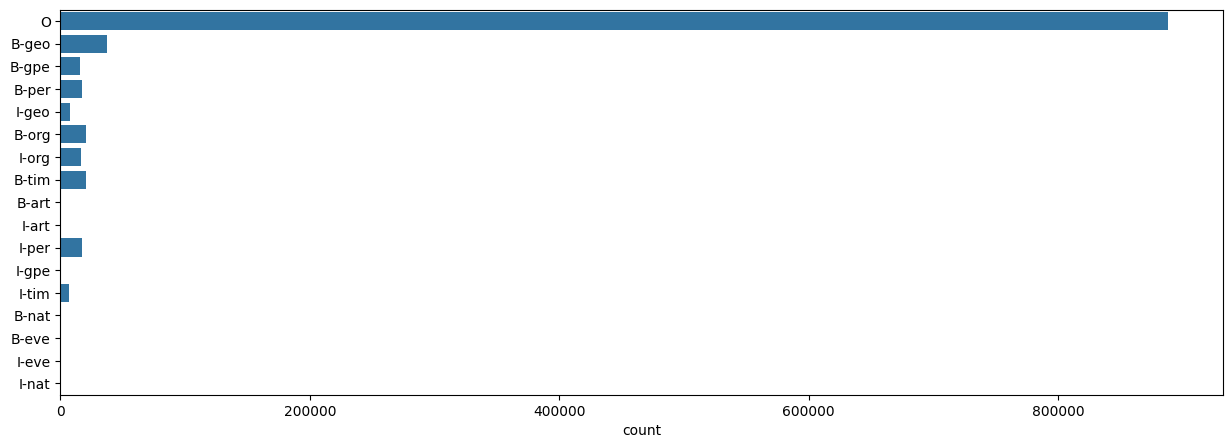

In [16]:
plt.figure(figsize=(15, 5))
sns.countplot(df.Tag.values)

In [17]:
num_tags = len(tags)
num_tags

17

In [18]:
agg_func = lambda s: [(w, t) for w, p, t in zip(s["Word"].values.tolist(), s["POS"].values.tolist(), s["Tag"].values.tolist())]
group = df.groupby("Sentence #").apply(agg_func)
lines = [s for s in group]

/tmp/ipykernel_1897/2701508946.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  group = df.groupby("Sentence #").apply(agg_func)


In [19]:
lines[0]

[('Thousands', 'O'),
 ('of', 'O'),
 ('demonstrators', 'O'),
 ('have', 'O'),
 ('marched', 'O'),
 ('through', 'O'),
 ('London', 'B-geo'),
 ('to', 'O'),
 ('protest', 'O'),
 ('the', 'O'),
 ('war', 'O'),
 ('in', 'O'),
 ('Iraq', 'B-geo'),
 ('and', 'O'),
 ('demand', 'O'),
 ('the', 'O'),
 ('withdrawal', 'O'),
 ('of', 'O'),
 ('British', 'B-gpe'),
 ('troops', 'O'),
 ('from', 'O'),
 ('that', 'O'),
 ('country', 'O'),
 ('.', 'O')]

In [20]:
sentences = [[tokens[0] for tokens in line] for line in lines]
tags = [[tokens[1] for tokens in line] for line in lines]

<Axes: ylabel='count'>

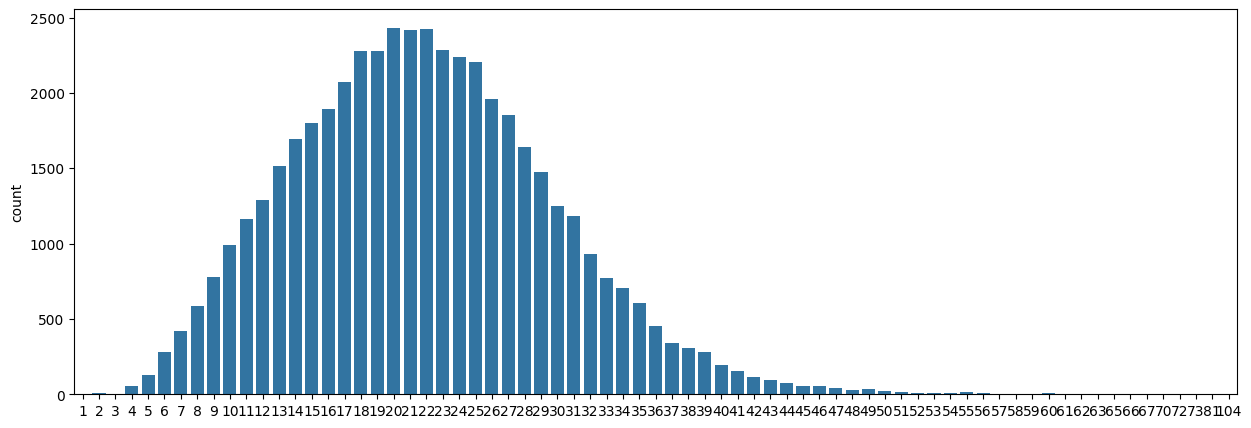

In [23]:
sen_lengths = [len(sent) for sent in sentences]
plt.figure(figsize=(15, 5))
sns.countplot(x=sen_lengths)

In [24]:
MAX_LEN = 60

In [25]:
tokenizer = BertTokenizer.from_pretrained('bert-base-cased')

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

In [26]:
# get the special tokens, it is required to use these while encoding in Field
init_token = tokenizer.cls_token
pad_token = tokenizer.pad_token
unk_token = tokenizer.unk_token

init_token_idx = tokenizer.convert_tokens_to_ids(init_token)
pad_token_idx = tokenizer.convert_tokens_to_ids(pad_token)
unk_token_idx = tokenizer.convert_tokens_to_ids(unk_token)

print(init_token_idx, pad_token_idx, unk_token_idx)

101 0 100


In [27]:
# limit the input tokens to max length - 1, [CLS] is the initial token
def convert_to_id(tokens, tokenizer, max_input_length=MAX_LEN):
    tokens = tokens[:max_input_length-1]
    tokens = [init_token_idx] + tokenizer.convert_tokens_to_ids(tokens)
    return tokens

def cut_tags(tag, max_input_length=MAX_LEN):
    tags = tag[:max_input_length-1]
    return tags

In [28]:
%%time
sentences_ids = [convert_to_id(line, tokenizer) for line in sentences]
tags = [cut_tags(tag) for tag in tags]

CPU times: user 611 ms, sys: 18 ms, total: 629 ms
Wall time: 631 ms


In [29]:
sentences_ids[0], tags[0]

([101,
  26159,
  1104,
  100,
  1138,
  9639,
  1194,
  1498,
  1106,
  5641,
  1103,
  1594,
  1107,
  5008,
  1105,
  4555,
  1103,
  10602,
  1104,
  1418,
  2830,
  1121,
  1115,
  1583,
  119],
 ['O',
  'O',
  'O',
  'O',
  'O',
  'O',
  'B-geo',
  'O',
  'O',
  'O',
  'O',
  'O',
  'B-geo',
  'O',
  'O',
  'O',
  'O',
  'O',
  'B-gpe',
  'O',
  'O',
  'O',
  'O',
  'O'])

In [30]:
class Vocabulary(object):
    def __init__(self):
        self.word2idx = {}
        self.idx2word = {}
        self.idx = 0

    def add_word(self, word):
        if not word in self.word2idx:
            self.word2idx[word] = self.idx
            self.idx2word[self.idx] = word
            self.idx += 1

    def __call__(self, word):
        return self.word2idx[word]

    def __len__(self):
        return len(self.word2idx)

In [31]:
def build_vocab(tags, threshold=5):
    """Build a simple vocabulary wrapper."""
    counter = Counter(chain(*tags))

    # If the word frequency is less than 'threshold', then the word is discarded.
    words = [word for word, cnt in counter.items() if cnt >= threshold]

    # Create a vocab wrapper and add some special tokens.
    vocab = Vocabulary()
    vocab.add_word('<pad>')

    # Add the words to the vocabulary.
    for i, word in enumerate(words):
        vocab.add_word(word)
    return vocab

In [33]:
tags_vocab = build_vocab(tags)
print("Total vocabulary size: {}".format(len(tags_vocab)))

Total vocabulary size: 18


In [34]:
tags_ids = [[tags_vocab('<pad>')] + [tags_vocab(t) for t in tag] for tag in tags]

In [35]:
train_sentences, valid_sentences, train_tags, valid_tags = train_test_split(sentences_ids, tags_ids, test_size=0.2, random_state=42)
valid_sentences, test_sentences, valid_tags, test_tags = train_test_split(valid_sentences, valid_tags, test_size=0.5, random_state=42)
len(train_sentences), len(valid_sentences), len(test_sentences)

(38367, 4796, 4796)

In [36]:
class NERDataset(data.Dataset):
    def __init__(self, sentences, tags):
        self.sentences = sentences
        self.tags = tags

    def __len__(self):
        return len(self.sentences)

    def __getitem__(self, item):
        sentence = self.sentences[item]
        tag = self.tags[item]

        return torch.LongTensor(sentence), torch.LongTensor(tag)

In [37]:
train_dataset = NERDataset(train_sentences, train_tags)
valid_dataset = NERDataset(valid_sentences, valid_tags)
test_dataset = NERDataset(test_sentences, test_tags)

In [38]:
train_dataset[0]

(tensor([  101,  1375,  3577,   100,  1433,  9667,  1145, 11770,   170,   100,
          2565,  1203, 18235, 19470,  7382,   117,  2637,  1106,  2561,   100,
          1207,  5448,   119]),
 tensor([0, 2, 6, 1, 1, 4, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]))

In [39]:
BATCH_SIZE = 64

In [40]:
def collate_fn(data):
    data.sort(key=lambda x: len(x[0]), reverse=True)
    sentences, tags = zip(*data)

    # Merge questions (from tuple of 1D tensor to 2D tensor).
    sent_lengths = [len(sent) for sent in sentences]
    inputs = torch.zeros(len(sentences), max(sent_lengths)).long()
    labels = torch.zeros(len(sentences), max(sent_lengths)).long()

    for i, (sent, lab) in enumerate(zip(sentences, tags)):
        end = sent_lengths[i]
        inputs[i, :end] = sent[:end]
        labels[i, :end] = lab[:end]

    return inputs, labels

In [41]:
train_data_loader = data.DataLoader(train_dataset, BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
valid_data_loader = data.DataLoader(valid_dataset, BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
test_data_loader = data.DataLoader(test_dataset, BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

In [42]:
sample = next(iter(train_data_loader))
sample[0].shape, sample[1].shape

(torch.Size([64, 45]), torch.Size([64, 45]))

In [45]:
class NERTagger(nn.Module):
    def __init__(self, output_dim, dropout):
        super().__init__()

        # bert model
        self.bert = BertModel.from_pretrained('bert-base-cased')

        # freeze BERT backbone
        for param in self.bert.parameters():
            param.requires_grad = False

        # bert model hidden size
        d_model = self.bert.config.to_dict()['hidden_size']

        # prediction layer
        self.fc = nn.Linear(d_model, output_dim)

        self.dropout = nn.Dropout(dropout)

    def forward(self, text):
        # text => [batch_size, seq_len]

        embedded = self.dropout(self.bert(text)[0])
        # only take the outputs, pooled output is not required
        # embedded => [batch_size, seq_len, d_model]

        predictions = self.fc(self.dropout(embedded))
        # predictions => [batch_size, seq_len, output_dim]

        return predictions

In [46]:
OUTPUT_DIM = len(tags_vocab)
DROPOUT = 0.4

model = NERTagger(OUTPUT_DIM, DROPOUT)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [47]:
model = model.to(device)

In [48]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'The model has {count_parameters(model):,} trainable parameters')

The model has 13,842 trainable parameters


In [49]:
LR = 5e-5
TAG_PAD_IDX = tags_vocab('<pad>')

optimizer = optim.Adam(model.parameters(), lr=LR)
criterion = nn.CrossEntropyLoss(ignore_index = TAG_PAD_IDX).to(device)

In [50]:
def train(model, iterator, criterion, optimizer):
    model.train()

    epoch_loss = 0

    for batch in iterator:
        text = batch[0].to(device)
        tags = batch[1].to(device)
        # text => [seq_len, batch_size]
        # tags => [seq_len, batch_size]

        optimizer.zero_grad()

        logits = model(text)
        # logits => [batch_size, seq_len, output_dim]

        logits = logits.view(-1, logits.shape[-1])
        # logits => [batch_size * seq_len, output_dim]

        tags = tags.view(-1)
        # tags => [batch_size * seq_len]

        loss = criterion(logits, tags)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    return epoch_loss / len(iterator)

In [51]:
def evaluate(model, iterator, criterion):
    model.eval()

    epoch_loss = 0

    with torch.no_grad():
        for batch in iterator:
            text = batch[0].to(device)
            tags = batch[1].to(device)
            # text => [batch_size, seq_len]
            # tags => [batch_size, seq_len]

            optimizer.zero_grad()

            logits = model(text)
            # logits => [batch_size, seq_len, output_dim]

            logits = logits.view(-1, logits.shape[-1])
            # logits => [batch_size * seq_len, output_dim]

            tags = tags.view(-1)
            # tags => [batch_size * seq_len]

            loss = criterion(logits, tags)
            epoch_loss += loss.item()

    return epoch_loss / len(iterator)

In [52]:
def epoch_time(start_time, end_time):
    elapsed_time = end_time - start_time
    elapsed_mins = int(elapsed_time / 60)
    elapsed_secs = int(elapsed_time - (elapsed_mins * 60))
    return elapsed_mins, elapsed_secs

In [59]:
N_EPOCHS = 10
best_valid_loss = float('inf')

for epoch in range(N_EPOCHS):

    start_time = time.time()

    train_loss = train(model, train_data_loader, criterion, optimizer)
    valid_loss = evaluate(model, valid_data_loader, criterion)

    end_time = time.time()

    epoch_mins, epoch_secs = epoch_time(start_time, end_time)

    if valid_loss < best_valid_loss:
        best_valid_loss = valid_loss
        torch.save(model.state_dict(), 'model.pt')

    print(f'Epoch: {epoch+1:02} | Epoch Time: {epoch_mins}m {epoch_secs}s')
    print(f'\tTrain Loss: {train_loss:.3f} | Val. Loss: {valid_loss:.3f}')

Epoch: 01 | Epoch Time: 1m 41s
	Train Loss: 0.450 | Val. Loss: 0.355
Epoch: 02 | Epoch Time: 1m 48s
	Train Loss: 0.427 | Val. Loss: 0.331
Epoch: 03 | Epoch Time: 1m 52s
	Train Loss: 0.412 | Val. Loss: 0.314
Epoch: 04 | Epoch Time: 1m 52s
	Train Loss: 0.400 | Val. Loss: 0.300
Epoch: 05 | Epoch Time: 1m 52s
	Train Loss: 0.390 | Val. Loss: 0.289
Epoch: 06 | Epoch Time: 1m 54s
	Train Loss: 0.384 | Val. Loss: 0.281
Epoch: 07 | Epoch Time: 1m 54s
	Train Loss: 0.379 | Val. Loss: 0.274
Epoch: 08 | Epoch Time: 1m 53s
	Train Loss: 0.375 | Val. Loss: 0.268
Epoch: 09 | Epoch Time: 1m 51s
	Train Loss: 0.372 | Val. Loss: 0.264
Epoch: 10 | Epoch Time: 1m 52s
	Train Loss: 0.369 | Val. Loss: 0.260


In [60]:
model.load_state_dict(torch.load('model.pt'))

<All keys matched successfully>

In [61]:
def cal_metrics(iterator):
    model.eval()
    epoch_loss = 0
    fin_outputs = []
    fin_targets = []

    with torch.no_grad():
        for batch in iterator:
            text = batch[0].to(device)
            tags = batch[1].to(device)
            # text => [seq_len, batch_size]
            # tags => [seq_len, batch_size]

            logits = model(text)
            # logits => [seq_len, batch_size, output_dim]

            predictions = logits.argmax(-1)

            fin_outputs.extend(predictions.detach().cpu().numpy().tolist())
            fin_targets.extend(tags.detach().cpu().numpy().tolist())

    assert len(fin_outputs) == len(fin_targets)
    mlb = MultiLabelBinarizer()
    trans_trg = mlb.fit_transform(fin_targets)
    trans_pred = mlb.transform(fin_outputs)

    cf = metrics.classification_report(trans_trg, trans_pred)
    print(cf)


In [62]:
cal_metrics(test_data_loader)

              precision    recall  f1-score   support

           0       0.00      0.00      0.00      4796
           1       1.00      1.00      1.00      4795
           2       0.88      0.86      0.87      2496
           3       0.92      0.76      0.83      1303
           4       0.99      0.71      0.83      1688
           5       0.81      0.32      0.46      1623
           6       0.78      0.43      0.55       595
           7       0.84      0.64      0.73      1361
           8       0.70      0.83      0.76      1071
           9       0.78      0.52      0.63       879
          10       0.93      0.37      0.53       395
          11       0.00      0.00      0.00        42
          12       0.00      0.00      0.00        25
          13       0.00      0.00      0.00        12
          14       0.00      0.00      0.00        15
          15       0.00      0.00      0.00         4
          16       0.00      0.00      0.00        31
          17       0.00    

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [64]:
def predict_ner(text, model, tokenizer, tags_vocab, device):
    model.eval()
    # Split text into simple sentences by period (could be improved, but sufficient for a basic passage)
    sentences = [s.strip() for s in text.split('.') if s.strip()]

    # Invert the vocab dictionary to map indices back to labels
    idx2tag = tags_vocab.idx2word

    for sentence in sentences:
        print(f"Sentence: {sentence}")
        # Tokenize sentence into words
        words = sentence.split()
        # Convert words to model ids
        tokens = [init_token_idx] + tokenizer.convert_tokens_to_ids(words[:MAX_LEN-1])
        print(f"  Tokens: {tokenizer.convert_ids_to_tokens(tokens)}")

        input_tensor = torch.LongTensor(tokens).unsqueeze(0).to(device)

        with torch.no_grad():
            predictions = model(input_tensor)
            # Argmax over prediction dimension
            predicted_tags_ids = predictions.argmax(-1).squeeze(0).cpu().numpy()

        # Align original words with predicted tags (ignoring [CLS] token)
        for word, tag_id in zip(words, predicted_tags_ids[1:]):
            tag_name = idx2tag.get(tag_id, 'O')
            print(f"  {word:<15} : {tag_name}")
        print("-" * 40)

# Example usage
passage = "In 2021, Apple released new devices in Cupertino. Tim Cook delivered the presentation."
predict_ner(passage, model, tokenizer, tags_vocab, device)

Sentence: In 2021, Apple released new devices in Cupertino
  Tokens: ['[CLS]', 'In', '[UNK]', 'Apple', 'released', 'new', 'devices', 'in', '[UNK]']
  In              : O
  2021,           : O
  Apple           : O
  released        : O
  new             : O
  devices         : O
  in              : O
  Cupertino       : O
----------------------------------------
Sentence: Tim Cook delivered the presentation
  Tokens: ['[CLS]', 'Tim', 'Cook', 'delivered', 'the', 'presentation']
  Tim             : B-per
  Cook            : I-per
  delivered       : O
  the             : O
  presentation    : O
----------------------------------------
